# Nivelación 0c — Álgebra lineal con una sola matriz

**RL a ciegas** · Nivelación 0c

Regla de esta clase: **una sola matriz**. Toda el álgebra lineal que necesitamos para el curso cabe en una matriz de la cueva: $P^\pi$, la que dice **adónde voy desde cada casilla** si elijo acciones al azar. Con ella vamos a calcular cuánto vale estar en cada casilla, de tres maneras distintas.

Hoy vamos a ver:

1. **Vectores**: el valor de la cueva como una lista de 60 números.
2. **Producto escalar**: el valor esperado del próximo paso, $p \cdot V$.
3. **Matrices**: $P^\pi$, una matriz **estocástica** (sus filas suman 1). Primero en una cueva chiquita, después en la grande.
4. **Matriz por vector**: un paso de propagación, $V_{k+1} = R + \gamma P V_k$.
5. **Identidad, inversa y sistemas lineales**: $V = (I - \gamma P)^{-1} R$ de un saque.
6. **Normas**: cuánto cambia $V$ de una vuelta a la otra.
7. **Autovalores**: por qué $\gamma$ controla la velocidad de convergencia.
8. **Gradiente**: encontrar $V$ bajando una pendiente (adelanto de la clase 8).

> Cómo usar este notebook: ejecutar las celdas en orden. Tarda menos de un minuto.

### Preparación

La primera celda escribe el entorno `cave_env.py`. La segunda importa lo necesario.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


In [2]:
from cave_env import CaveEnv, ACTION_NAMES
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
np.set_printoptions(precision=3, suppress=True)

### Herramientas

Funciones para armar $P^\pi$ y $R^\pi$ a partir del entorno, medir distancias, dibujar matrices con sus números y dibujar valores sobre la cueva (en escala logarítmica cuando hace falta). **No hace falta leerla.**

In [3]:
# @title Herramientas (plegada)
# Herramientas: no hace falta leer esto
import time
import matplotlib.patheffects as pe

CUEVA_CHICA = ["#######",
               "#S...G#",
               "#.#####",
               "#.....#",
               "#######"]


def matriz_politica(env, pi_a=None):
    '''P^pi[s, s2] = sum_a pi(a) P[s, a, s2]  y  R^pi[s] = sum_a pi(a) R[s, a]. Por defecto, acciones al azar.'''
    pi_a = np.full(env.nA, 1 / env.nA) if pi_a is None else np.asarray(pi_a, dtype=float)
    return np.einsum("a,sat->st", pi_a, env.P), env.R @ pi_a


def distancias(env):
    '''Pasos mínimos desde cada casilla hasta la salida (búsqueda en anchura).'''
    d = np.full(env.nS, np.inf); d[env.goal] = 0
    frente = [env.goal]
    while frente:
        nuevo = []
        for s in frente:
            for s2 in range(env.nS):
                if np.isinf(d[s2]) and any(env._move(s2, a)[0] == s for a in range(4)):
                    d[s2] = d[s] + 1; nuevo.append(s2)
        frente = nuevo
    return d


def iterar(P, R, gamma, K, V0=None):
    '''Devuelve [V_0, V_1, ..., V_K] con V_{k+1} = R + gamma P V_k.'''
    V = np.zeros(len(R)) if V0 is None else V0.copy()
    hist = [V.copy()]
    for _ in range(K):
        V = R + gamma * P @ V
        hist.append(V.copy())
    return hist


def log10_seguro(v, piso=1e-12):
    '''log10 de un vector; donde el valor es ~0 devuelve NaN (queda negro en el dibujo).'''
    v = np.asarray(v, dtype=float)
    out = np.full_like(v, np.nan)
    m = v > piso
    out[m] = np.log10(v[m])
    return out


def plot_cave(env, values=None, ax=None, title=None, cmap="magma", clim=None, mark=None,
              numbers=False, fmt="{:.2f}", path=None, policy=None):
    '''env.plot + escala de color elegible, círculo opcional en una casilla y números opcionales.'''
    ax = env.plot(values=values, ax=ax, title=title, cmap=cmap, path=path, policy=policy)
    if values is not None and clim is not None:
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        r, c = env.free[mark]
        ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_row(env, values_list, titles, cmap="magma", clim=None, size=4.0, ncols=None, marks=None):
    n = len(values_list)
    ncols = n if ncols is None else ncols
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, (size * env.H / env.W + 0.6) * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    for i, ax in enumerate(axes[:n]):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap, clim=clim,
                  mark=None if marks is None else marks[i])
    plt.tight_layout(); plt.show()


def etiquetar_estados(env, ax):
    '''Escribe el número de estado en cada casilla.'''
    for s, (r, c) in enumerate(env.free):
        ax.text(c, r + 0.28, str(s), ha="center", va="center", fontsize=9, color="#f1c40f", weight="bold",
                path_effects=[pe.withStroke(linewidth=2, foreground="black")])


def dibujar_matriz(M, ax, titulo, fmt="{:.2f}", cmap="Blues", vmin=None, vmax=None, anotar=True):
    M = np.asarray(M)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    if anotar:
        top = np.nanmax(np.abs(M)) if vmax is None else vmax
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if abs(M[i, j]) > 1e-9:
                    ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=7,
                            color="w" if abs(M[i, j]) > 0.6 * top else "k")
    ax.set_title(titulo); ax.set_xlabel("columna  s'"); ax.set_ylabel("fila  s")
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    ax.tick_params(labelsize=7)
    return im

## Paso 1 — Vectores: la cueva como 60 números

La cueva tiene 60 casillas libres. Si a cada una le asignamos un número, tenemos un **vector** $V \in \mathbb{R}^{60}$. El ejemplo de hoy: $V(s) = \gamma^{d(s)}$, donde $d(s)$ es la distancia (en pasos) de la casilla $s$ a la salida. Cerca de la salida vale casi 1; lejos, casi 0. (Es el valor de una política perfecta; lo vamos a reencontrar en la clase 4.)

El mismo vector se puede dibujar de dos maneras: como una **tira** de 60 números en el orden de los estados, o **sobre la cueva**.

forma de V: (60,)    primeros 6 valores: [0.122 0.135 0.15  0.167 0.254 0.282]


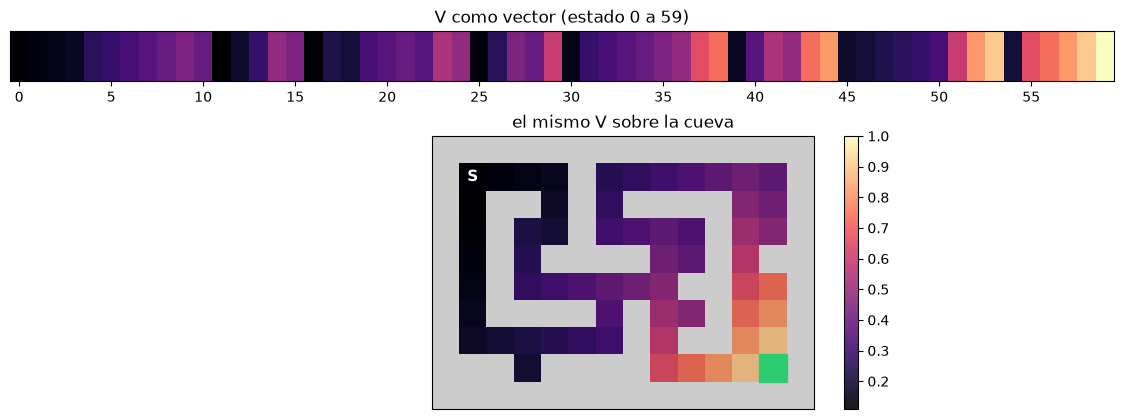

In [4]:
env = CaveEnv()
gamma = 0.9
d = distancias(env)
V = gamma ** d
print("forma de V:", V.shape, "   primeros 6 valores:", V[:6])

fig = plt.figure(figsize=(12, 4.2))
ax1 = fig.add_axes([0.04, 0.80, 0.92, 0.12])
ax1.imshow(V[None, :], cmap="magma", aspect="auto")
ax1.set_yticks([]); ax1.set_xticks(range(0, 60, 5)); ax1.set_title("V como vector (estado 0 a 59)")
ax2 = fig.add_axes([0.25, 0.02, 0.5, 0.65])
plot_cave(env, values=V, ax=ax2, title="el mismo V sobre la cueva")
plt.show()

Pasar de un dibujo al otro es pasar de **vector** a **grilla** y de vuelta. `env.to_grid` pone cada número en su casilla (las paredes quedan como NaN); para volver, alcanza con indexar la grilla con las coordenadas de las casillas libres.

In [5]:
G = env.to_grid(V)                        # vector (60,) -> grilla (10, 14)
filas, cols = np.array(env.free).T        # coordenadas de los 60 estados
V_de_vuelta = G[filas, cols]              # grilla -> vector
print("grilla:", G.shape, "  vector:", V_de_vuelta.shape, "  ¿es el mismo vector?", np.allclose(V, V_de_vuelta))

print("operaciones elemento a elemento: γ·V =", (gamma * V)[:4], "...   V + V =", (V + V)[:4], "...")

grilla: (10, 14)   vector: (60,)   ¿es el mismo vector? True
operaciones elemento a elemento: γ·V = [0.109 0.122 0.135 0.15 ] ...   V + V = [0.243 0.27  0.3   0.334] ...


## Paso 2 — Producto escalar: el valor esperado del próximo paso

Con piso resbaloso (`slip=0.2`), desde la casilla del círculo intento ↓. Hay tres destinos posibles, cada uno con su probabilidad: eso es un vector $p$ (casi todo ceros). ¿Cuánto vale, **en promedio**, la casilla donde voy a caer? Multiplico casilla por casilla y sumo:

Izquierda: $p$. Centro: $V$. Derecha: el producto elemento a elemento $p_i V_i$.

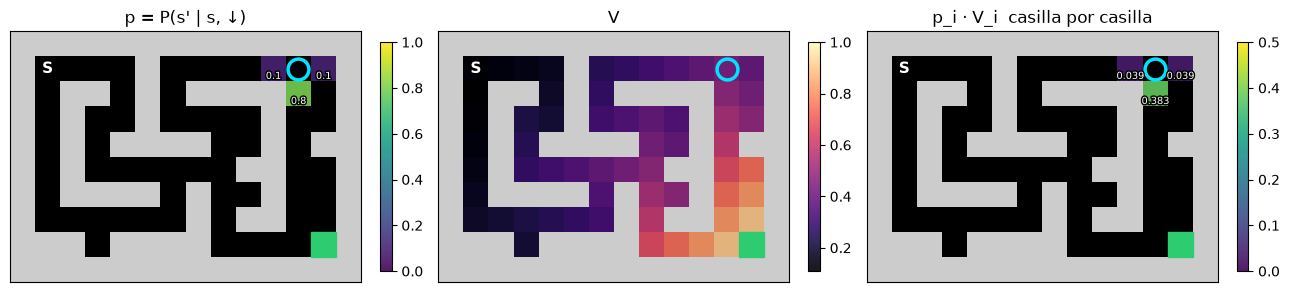

p · V = 0.4601    (= suma de p_i V_i = 0.4601 )
   0.1 × V(1, 10) = 0.1 × 0.387 = 0.0387
   0.1 × V(1, 12) = 0.1 × 0.387 = 0.0387
   0.8 × V(2, 11) = 0.8 × 0.478 = 0.3826


In [6]:
env_r = CaveEnv(slip=0.2)
s, ABAJO = env.pos2s[(1, 11)], 2
p = env_r.P[s, ABAJO]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
plot_cave(env, values=np.where(p > 0, p, np.nan), ax=axs[0], cmap="viridis", clim=(0, 1), mark=s,
          numbers=True, fmt="{:.1f}", title="p = P(s' | s, ↓)")
plot_cave(env, values=V, ax=axs[1], mark=s, title="V")
plot_cave(env, values=np.where(p > 0, p * V, np.nan), ax=axs[2], cmap="viridis", clim=(0, 0.5), mark=s,
          numbers=True, fmt="{:.3f}", title="p_i · V_i  casilla por casilla")
plt.tight_layout(); plt.show()
print("p · V =", round(float(p @ V), 4), "   (= suma de p_i V_i =", round(float(np.sum(p * V)), 4), ")")
for s2 in np.flatnonzero(p):
    print(f"   {p[s2]:.1f} × V{env.free[s2]} = {p[s2]:.1f} × {V[s2]:.3f} = {p[s2] * V[s2]:.4f}")

Eso es el **producto escalar** (*dot product*):

$$p \cdot V = \sum_{i} p_i\, V_i \qquad \text{(en NumPy: } \texttt{p @ V}\text{)}$$

Cuando $p$ es una distribución de probabilidad, $p \cdot V$ es un **valor esperado**: el promedio de $V$ pesado por la chance de caer en cada casilla. Es la cuenta que aparece en todas las ecuaciones de Bellman.

## Paso 3 — La matriz $P^\pi$: adónde voy desde cada casilla

Si apilamos el vector $p$ de **cada** casilla, una fila por casilla, obtenemos una **matriz**. Con acciones al azar ($\pi(a) = 1/4$):

$$P^\pi[s, s'] = \sum_a \pi(a)\, P(s' \mid s, a)$$

Empecemos por una cueva chiquita de 11 casillas, para poder leer la matriz entera. Arriba, la cueva con el número de cada estado (en amarillo); abajo, $P^\pi$ con sus números.

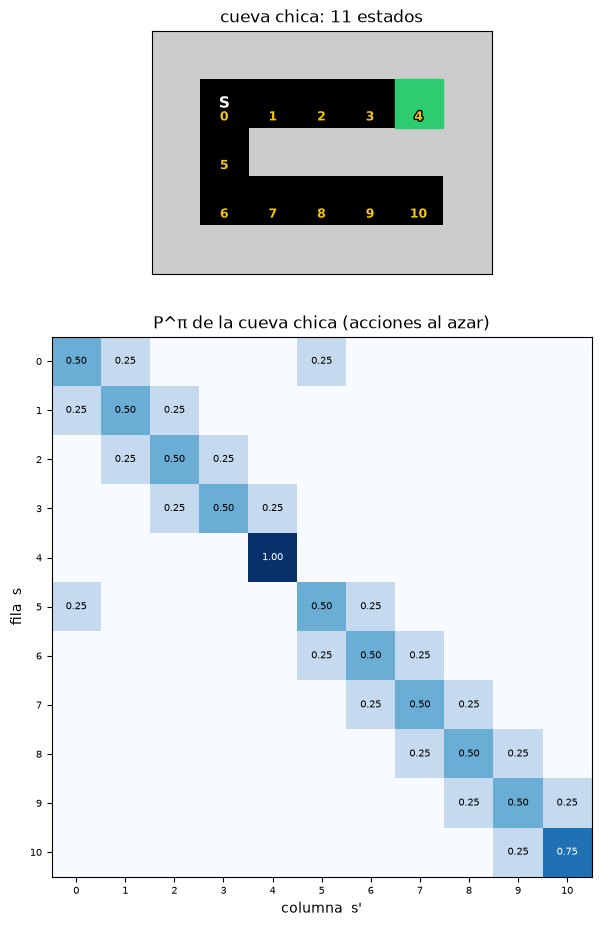

suma de cada fila: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
chica = CaveEnv(cave_map=CUEVA_CHICA)
Pc, Rc = matriz_politica(chica)

fig = plt.figure(figsize=(12, 9))
ax1 = fig.add_axes([0.3, 0.70, 0.4, 0.27])
plot_cave(chica, ax=ax1, title="cueva chica: 11 estados"); etiquetar_estados(chica, ax1)
ax2 = fig.add_axes([0.08, 0.03, 0.84, 0.6])
dibujar_matriz(Pc, ax2, "P^π de la cueva chica (acciones al azar)")
plt.show()
print("suma de cada fila:", Pc.sum(axis=1))

Cómo leerla: la **fila** $s$ es "desde dónde salgo" y la **columna** $s'$ es "adónde llego".

- Fila 0 (el inicio S): con 1/2 me quedo (↑ y ← chocan), con 1/4 voy a 1 (→) y con 1/4 a 5 (↓).
- Fila 4 (la salida G): un 1 en la diagonal. La salida es **absorbente**: una vez adentro, me quedo.
- Todas las filas suman 1, porque desde cualquier casilla **algún** lugar tengo que llegar. Una matriz de números $\geq 0$ con filas que suman 1 se llama **estocástica**.
- Casi todo es cero: solo puedo llegar a casillas vecinas. Es una matriz **rala** (*sparse*).

Ahora la matriz de la cueva grande: 60 × 60. Ya no se pueden leer los números, pero se ve la estructura. A la derecha, una fila cualquiera vuelta a dibujar sobre la cueva.

P^π: (60, 60)   R^π: (60,)   filas suman 1: True   fracción de ceros: 0.947


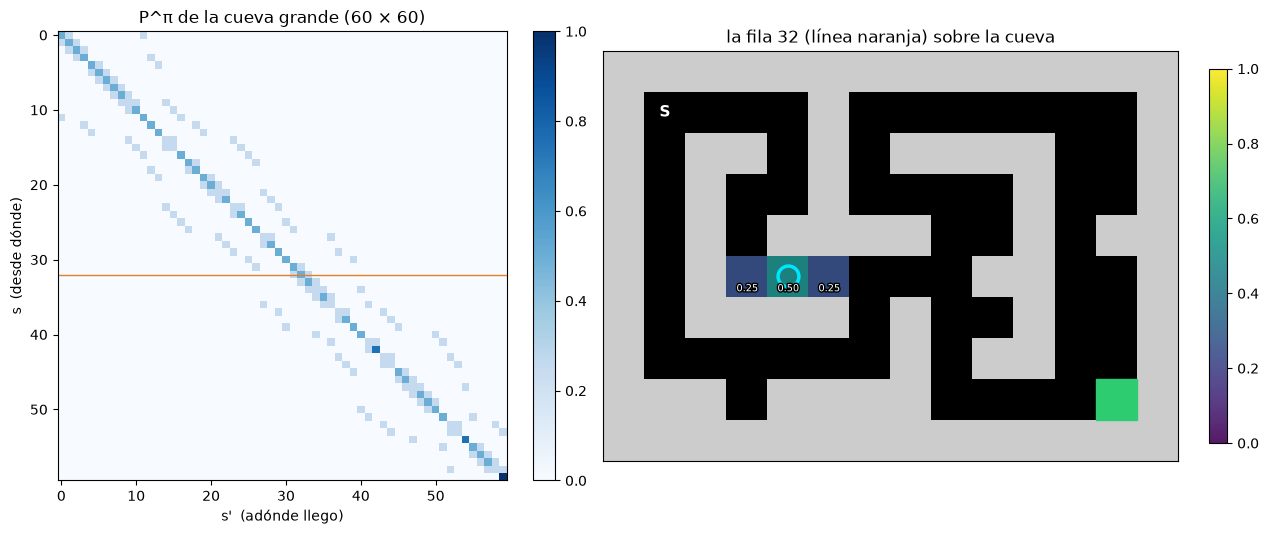

In [8]:
P, R = matriz_politica(env)
print("P^π:", P.shape, "  R^π:", R.shape, "  filas suman 1:", np.allclose(P.sum(axis=1), 1),
      "  fracción de ceros:", round(float(np.mean(P == 0)), 3))

fila = env.pos2s[(5, 4)]
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
im = axs[0].imshow(P, cmap="Blues", vmin=0, vmax=1)
axs[0].axhline(fila, color="#e67e22", lw=1)
axs[0].set_title("P^π de la cueva grande (60 × 60)"); axs[0].set_xlabel("s'  (adónde llego)"); axs[0].set_ylabel("s  (desde dónde)")
plt.colorbar(im, ax=axs[0], fraction=0.046)
plot_cave(env, values=np.where(P[fila] > 0, P[fila], np.nan), ax=axs[1], cmap="viridis", clim=(0, 1),
          mark=fila, numbers=True, title=f"la fila {fila} (línea naranja) sobre la cueva")
plt.tight_layout(); plt.show()

La diagonal gruesa son los "me quedo donde estoy" (choques); las diagonales vecinas, los movimientos a izquierda y derecha (estados consecutivos en una fila de la cueva); los puntos sueltos, los movimientos arriba y abajo. La matriz **es** el mapa de la cueva, escrito de otra manera.

## Paso 4 — Matriz por vector: un paso de propagación

Multiplicar una matriz por un vector es hacer **un producto escalar por cada fila**:

$$(P V)[s] = \sum_{s'} P[s, s']\, V[s'] = \text{valor esperado del próximo paso, saliendo de } s.$$

Con eso, la ecuación de Bellman de una política (clase 3) es una sola línea: el valor de cada casilla es la recompensa inmediata más el valor esperado de donde caigo, descontado.

$$V_{k+1} = R + \gamma\, P\, V_k$$

Empecemos con $V_0 = 0$ y apliquemos la regla una y otra vez. Usamos $\gamma = 0{,}99$ y, como el valor de caminar al azar es muy chico lejos de la salida, lo pintamos en **escala logarítmica** ($\log_{10} V$; negro = todavía 0).

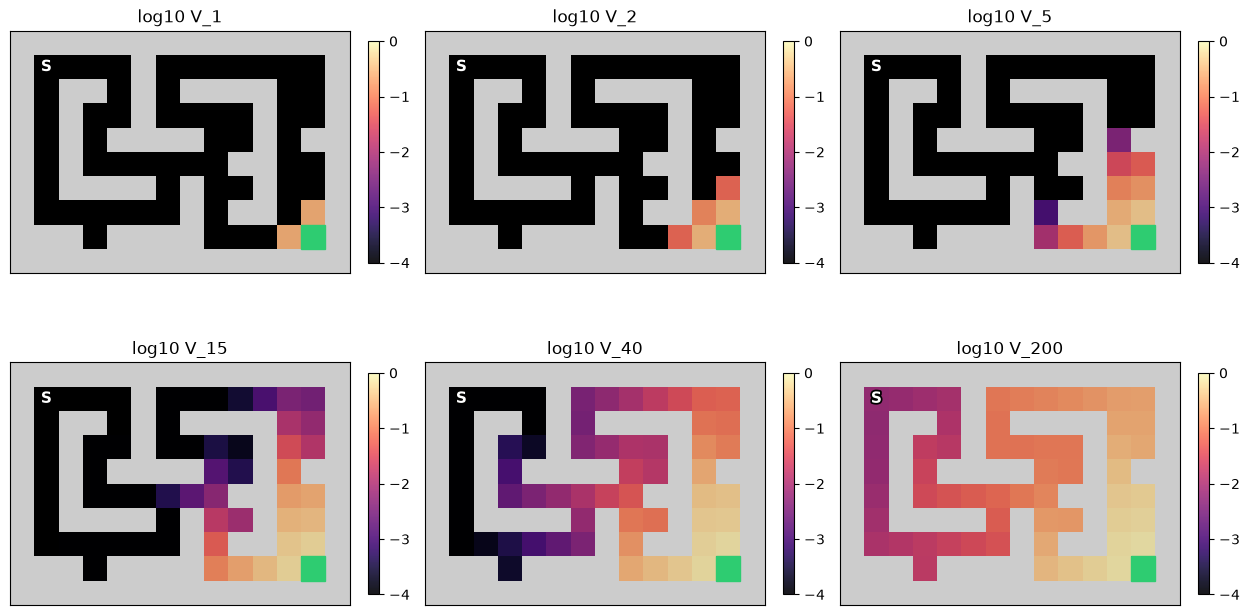

In [9]:
gamma = 0.99
hist = iterar(P, R, gamma, K=200)
ks = [1, 2, 5, 15, 40, 200]
plot_row(env, [log10_seguro(hist[k]) for k in ks], [f"log10 V_{k}" for k in ks],
         clim=(-4, 0), size=4.2, ncols=3)

El valor **nace en la salida y se derrama hacia atrás**: cada multiplicación por $P$ lo corre una casilla más. En la vuelta 20 llega por primera vez a S (la salida está a 20 pasos), aunque tan chiquito que todavía no entra en la escala del dibujo; después sigue creciendo, cada vez más despacio.

La misma matriz sirve para otra cosa si multiplicamos **del otro lado**. Si $d_t$ es la probabilidad de estar en cada casilla en el paso $t$ (un vector fila), entonces $d_{t+1} = d_t\, P$ empuja esa probabilidad **hacia adelante**, desde S. Valor hacia atrás, probabilidad hacia adelante: **una sola matriz**.

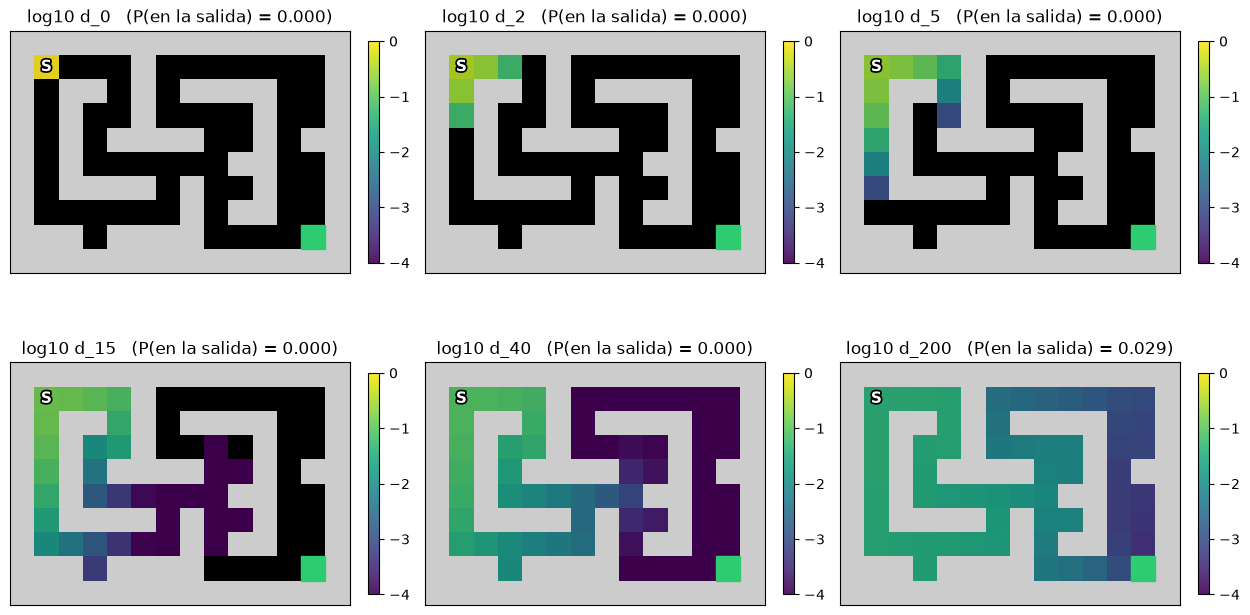

In [10]:
d_t = np.zeros(env.nS); d_t[env.start] = 1.0
dist = [d_t]
for _ in range(200):
    d_t = d_t @ P
    dist.append(d_t)
ts = [0, 2, 5, 15, 40, 200]
plot_row(env, [log10_seguro(dist[t]) for t in ts],
         [f"log10 d_{t}   (P(en la salida) = {dist[t][env.goal]:.3f})" for t in ts],
         cmap="viridis", clim=(-4, 0), size=4.2, ncols=3)

## Paso 5 — Identidad, inversa y sistemas lineales

¿Hace falta iterar? Si $V$ ya no cambia, cumple $V = R + \gamma P V$. Pasando términos:

$$(I - \gamma P)\, V = R \quad\Longrightarrow\quad V = (I - \gamma P)^{-1} R$$

- $I$ es la **identidad**: unos en la diagonal, ceros afuera. Multiplicar por $I$ no cambia nada ($IV = V$).
- $(I - \gamma P)^{-1}$ es la **inversa**: la matriz que "deshace" a $I - \gamma P$. Existe porque $\gamma < 1$ (lo vemos en el Paso 7).

Veamos las cuatro matrices en la cueva chica.

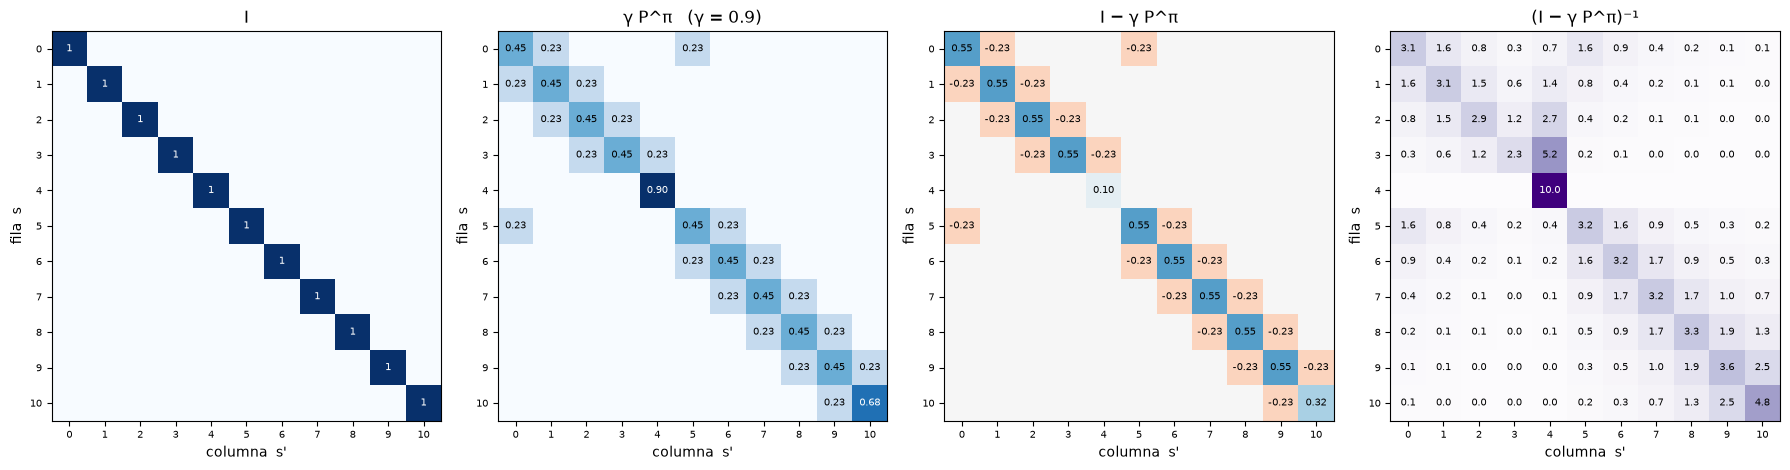

¿(I − γP) · inversa = I? True


In [11]:
g = 0.9
I = np.eye(chica.nS)
A_chica = I - g * Pc
inv_chica = np.linalg.inv(A_chica)

fig, axs = plt.subplots(1, 4, figsize=(18, 4.6))
dibujar_matriz(I, axs[0], "I", fmt="{:.0f}")
dibujar_matriz(g * Pc, axs[1], f"γ P^π   (γ = {g})")
dibujar_matriz(A_chica, axs[2], "I − γ P^π", cmap="RdBu", vmin=-1, vmax=1)
dibujar_matriz(inv_chica, axs[3], "(I − γ P^π)⁻¹", fmt="{:.1f}", cmap="Purples")
plt.tight_layout(); plt.show()
print("¿(I − γP) · inversa = I?", np.allclose(A_chica @ inv_chica, I))

La inversa tiene una lectura concreta: el número en la fila $s$, columna $s'$ es **cuántas veces (descontadas) voy a pasar por $s'$ si salgo de $s$**. Por eso la diagonal es grande (cada casilla se cuenta a sí misma) y la columna 4 (la salida) acumula todo lo que llega y no se va más.

En la práctica **no** se calcula la inversa: se resuelve el sistema $(I - \gamma P)V = R$ con `np.linalg.solve`, que es más rápido y más preciso. Comparemos con la iteración del Paso 4 en la cueva grande.

solve:      V(S) = 0.013586   (1.92 ms)
3000 iter.: V(S) = 0.013586   (12.1 ms)
máxima diferencia: 2.3314683517128287e-15


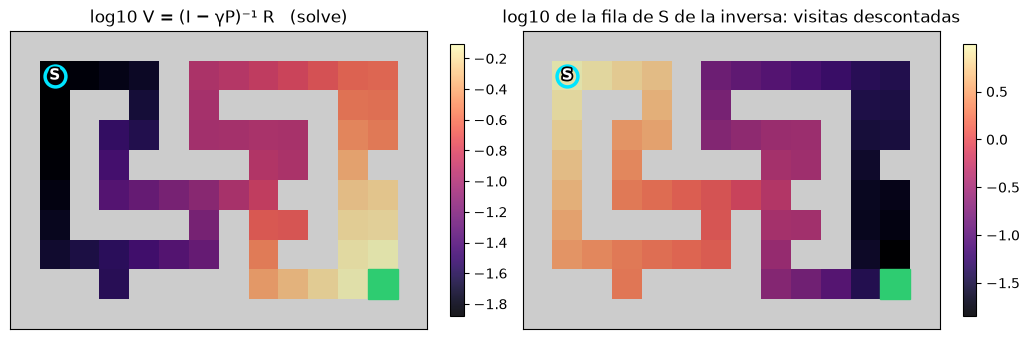

In [12]:
t0 = time.perf_counter()
V_exacto = np.linalg.solve(np.eye(env.nS) - gamma * P, R)
t_solve = time.perf_counter() - t0

t0 = time.perf_counter()
V_iter = iterar(P, R, gamma, K=3000)[-1]
t_iter = time.perf_counter() - t0

print(f"solve:      V(S) = {V_exacto[env.start]:.6f}   ({t_solve * 1000:.2f} ms)")
print(f"3000 iter.: V(S) = {V_iter[env.start]:.6f}   ({t_iter * 1000:.1f} ms)")
print("máxima diferencia:", np.abs(V_exacto - V_iter).max())

visitas = np.linalg.inv(np.eye(env.nS) - gamma * P)[env.start]
plot_row(env, [log10_seguro(V_exacto), log10_seguro(visitas)],
         ["log10 V = (I − γP)⁻¹ R   (solve)", "log10 de la fila de S de la inversa: visitas descontadas"],
         clim=None, size=5.2, marks=[env.start, env.start])

Las dos formas dan lo mismo. A la derecha, la fila de S de la inversa: un agente al azar que sale de S pasa **mucho** tiempo cerca del inicio y casi nada cerca de la salida. Con 60 estados resolver el sistema es instantáneo; con millones de estados (o con estados continuos) ya no se puede, y por eso RL usa casi siempre la versión iterativa.

## Paso 6 — Normas: ¿cuánto cambia $V$?

Para saber cuándo cortar la iteración necesitamos medir **el tamaño de un vector** con un solo número: una **norma**. Tres comunes, para un vector $x$:

$$\|x\|_1 = \sum_i |x_i| \qquad \|x\|_2 = \sqrt{\textstyle\sum_i x_i^2} \qquad \|x\|_\infty = \max_i |x_i|$$

En RL se usa mucho la última ("la casilla que más cambió"). Midamos $\|V_{k+1} - V_k\|$ en cada vuelta.

en NumPy: np.linalg.norm(x, 1), np.linalg.norm(x), np.linalg.norm(x, np.inf)


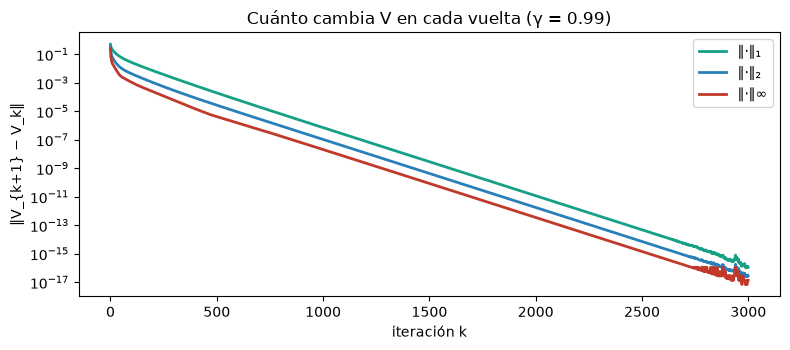

In [13]:
hist = iterar(P, R, gamma, K=3000)
dif = np.diff(np.array(hist), axis=0)              # V_{k+1} - V_k para cada k
normas = {"‖·‖₁": np.abs(dif).sum(axis=1), "‖·‖₂": np.sqrt((dif ** 2).sum(axis=1)), "‖·‖∞": np.abs(dif).max(axis=1)}
print("en NumPy: np.linalg.norm(x, 1), np.linalg.norm(x), np.linalg.norm(x, np.inf)")

fig, ax = plt.subplots(figsize=(8, 3.6))
for (nom, n), col in zip(normas.items(), ["#16a085", "#2980b9", "#c0392b"]):
    ax.semilogy(n, color=col, lw=2, label=nom)
ax.set_xlabel("iteración k"); ax.set_ylabel("‖V_{k+1} − V_k‖")
ax.set_title(f"Cuánto cambia V en cada vuelta (γ = {gamma})"); ax.legend()
plt.tight_layout(); plt.show()

Las tres normas cuentan la misma historia: después de un arranque, los cambios caen en **línea recta en escala logarítmica**, o sea, se multiplican por un número fijo menor que 1 en cada vuelta (caída **geométrica**). ¿Qué número? Lo dice el próximo paso.

## Paso 7 — Autovalores: por qué $\gamma$ manda

Un **autovector** (*eigenvector*) de una matriz es una dirección que la matriz solo estira: $P v = \lambda v$; el factor $\lambda$ es su **autovalor**. Dos autovectores de $P^\pi$ se adivinan sin hacer cuentas:

- el vector de **unos**: como las filas suman 1, $P\,\mathbf{1} = \mathbf{1}$ (autovalor 1);
- del otro lado, "estar en la salida con probabilidad 1": como es absorbente, $d\,P = d$ (también autovalor 1).

Calculemos todos los autovalores de $P^\pi$.

¿P·1 = 1? True
¿e_salida·P = e_salida? True
los 4 autovalores más grandes: [1.    0.999 0.995 0.987]   ¿todos reales? True


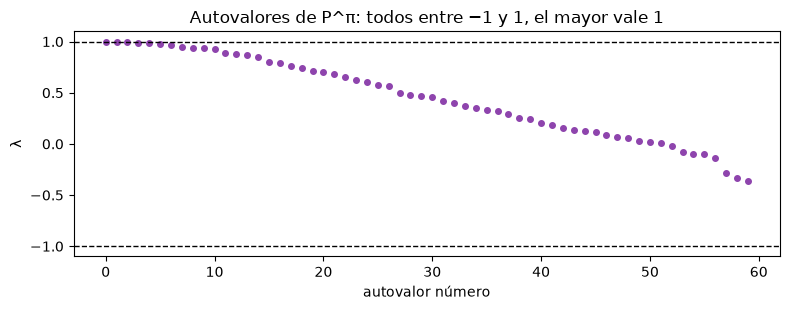

In [14]:
lam = np.linalg.eigvals(P)
lam = lam[np.argsort(-np.abs(lam))]
print("¿P·1 = 1?", np.allclose(P @ np.ones(env.nS), 1))
e_meta = np.eye(env.nS)[env.goal]
print("¿e_salida·P = e_salida?", np.allclose(e_meta @ P, e_meta))
print("los 4 autovalores más grandes:", lam[:4].real.round(4), "  ¿todos reales?", np.allclose(lam.imag, 0))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.sort(lam.real)[::-1], "o", color="#8e44ad", ms=4)
ax.axhline(1, color="k", ls="--", lw=1); ax.axhline(-1, color="k", ls="--", lw=1)
ax.set_xlabel("autovalor número"); ax.set_ylabel("λ")
ax.set_title("Autovalores de P^π: todos entre −1 y 1, el mayor vale 1")
plt.tight_layout(); plt.show()

Ningún autovalor de una matriz estocástica pasa de 1 en valor absoluto: $P$ **promedia**, nunca agranda. Entonces $\gamma P$ achica todo por lo menos un factor $\gamma$, y el error de la iteración se multiplica por (a lo sumo) $\gamma$ en cada vuelta:

$$\|V_k - V\|_\infty \le \gamma^k\, \|V_0 - V\|_\infty \quad\Longrightarrow\quad \log \|V_k - V\| \approx k \log\gamma + \text{constante}$$

Una recta de **pendiente $\log\gamma$**. Comprobémoslo con varios $\gamma$.

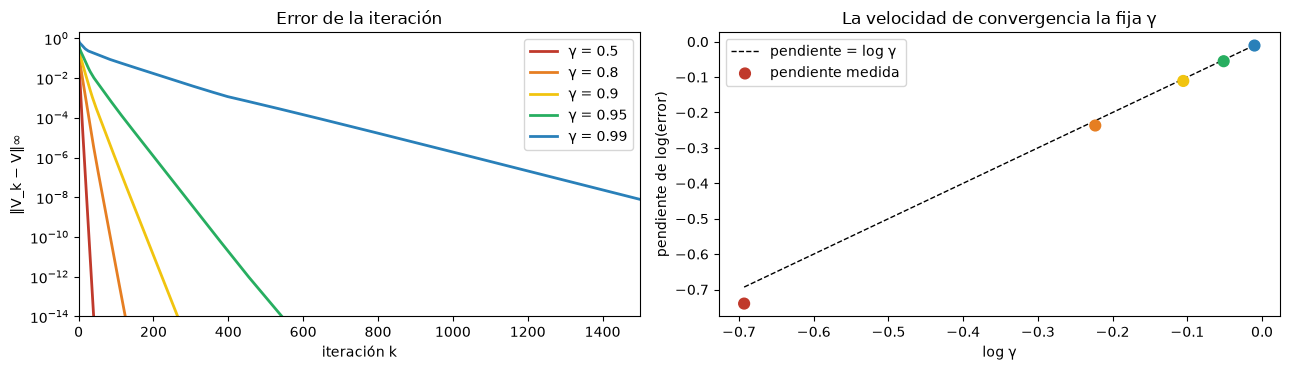

γ = 0.5:  pendiente medida = -0.7398   log γ = -0.6931   (vueltas para dividir el error por 10 ≈ 3)
γ = 0.8:  pendiente medida = -0.2367   log γ = -0.2231   (vueltas para dividir el error por 10 ≈ 10)
γ = 0.9:  pendiente medida = -0.1109   log γ = -0.1054   (vueltas para dividir el error por 10 ≈ 21)
γ = 0.95:  pendiente medida = -0.0552   log γ = -0.0513   (vueltas para dividir el error por 10 ≈ 42)
γ = 0.99:  pendiente medida = -0.0109   log γ = -0.0101   (vueltas para dividir el error por 10 ≈ 212)


In [15]:
gammas = [0.5, 0.8, 0.9, 0.95, 0.99]
colores = ["#c0392b", "#e67e22", "#f1c40f", "#27ae60", "#2980b9"]
pendientes = []
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for g, col in zip(gammas, colores):
    V_g = np.linalg.solve(np.eye(env.nS) - g * P, R)
    err = np.array([np.abs(Vk - V_g).max() for Vk in iterar(P, R, g, K=1500)])
    axs[0].semilogy(err, color=col, lw=2, label=f"γ = {g}")
    k = np.flatnonzero((err < 1e-3 * err[0]) & (err > 1e-12 * err[0]))      # tramo recto, lejos del arranque y del redondeo
    pendientes.append(np.polyfit(k, np.log(err[k]), 1)[0])
axs[0].set_xlim(0, 1500); axs[0].set_ylim(1e-14, 2)
axs[0].set_xlabel("iteración k"); axs[0].set_ylabel("‖V_k − V‖∞"); axs[0].set_title("Error de la iteración"); axs[0].legend()

xs = np.log(gammas)
axs[1].plot(xs, xs, "k--", lw=1, label="pendiente = log γ")
axs[1].scatter(xs, pendientes, c=colores, s=60, zorder=3, label="pendiente medida")
axs[1].set_xlabel("log γ"); axs[1].set_ylabel("pendiente de log(error)")
axs[1].set_title("La velocidad de convergencia la fija γ"); axs[1].legend()
plt.tight_layout(); plt.show()
for g, m in zip(gammas, pendientes):
    print(f"γ = {g}:  pendiente medida = {m:+.4f}   log γ = {np.log(g):+.4f}   (vueltas para dividir el error por 10 ≈ {np.log(10) / -m:.0f})")

Los puntos caen sobre la recta o apenas por debajo: **la velocidad la fija $\gamma$**. ($\gamma^k$ es el peor caso; la matriz de verdad ayuda un poquito más, porque su segundo autovalor, $\approx 0{,}999$, es apenas menor que 1.) La moraleja práctica: un $\gamma$ cercano a 1 mira lejos en el futuro, pero hace que todo converja **mucho** más lento. Con $\gamma = 0{,}99$ hacen falta unas 200 vueltas para ganar un solo dígito de precisión.

## Paso 8 — Gradiente: encontrar $V$ bajando una pendiente

Una tercera forma, que es la que se usa con redes neuronales. Definimos el **error de Bellman**: cuánto le falta a una tabla $V$ cualquiera para cumplir la ecuación,

$$L(V) = \tfrac{1}{2}\, \big\| R + \gamma P V - V \big\|_2^2 .$$

$L$ es una función de 60 variables que vale 0 justo en la solución. Su **gradiente** $\nabla L$ (el vector de las 60 derivadas parciales) apunta hacia donde $L$ sube más rápido; para bajar, damos pasos chiquitos en contra:

$$V \leftarrow V - \alpha\, \nabla L(V), \qquad \nabla L(V) = (\gamma P - I)^\top \big(R + \gamma P V - V\big).$$

($^\top$ es la **transpuesta**: filas por columnas.) Probemos con $\gamma = 0{,}9$, empezando de $V = 0$.

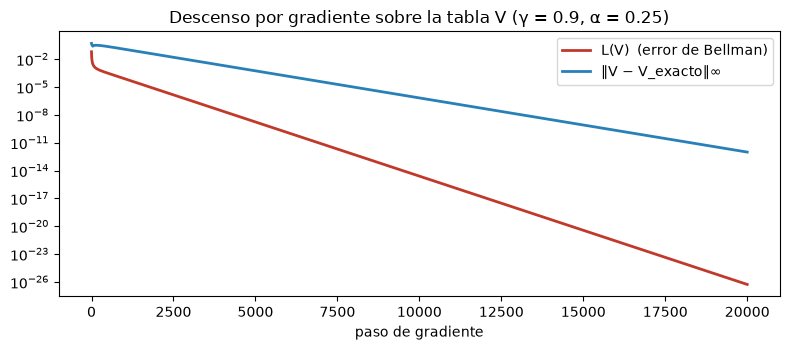

máxima diferencia final con solve: 9.657153983012273e-13


In [16]:
g = 0.9
A = g * P - np.eye(env.nS)                       # para escribir el error como A V + R
V_obj = np.linalg.solve(-A, R)                   # la respuesta, para comparar
alpha = 0.25

V_gd = np.zeros(env.nS)
perdida, distancia = [], []
for it in range(20_000):
    error = R + A @ V_gd                         # error de Bellman, casilla por casilla
    perdida.append(0.5 * error @ error)
    distancia.append(np.abs(V_gd - V_obj).max())
    V_gd = V_gd - alpha * (A.T @ error)          # paso de descenso por gradiente

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.semilogy(perdida, color="#c0392b", lw=2, label="L(V)  (error de Bellman)")
ax.semilogy(distancia, color="#2980b9", lw=2, label="‖V − V_exacto‖∞")
ax.set_xlabel("paso de gradiente"); ax.set_title(f"Descenso por gradiente sobre la tabla V (γ = {g}, α = {alpha})")
ax.legend(); plt.tight_layout(); plt.show()
print("máxima diferencia final con solve:", np.abs(V_gd - V_obj).max())

Funciona, pero es **lento**: miles de pasos para algo que `solve` hace de un saque. Y fijate en un detalle: el error de Bellman (rojo) se desploma en los primeros pasos, pero la distancia a la respuesta (azul) casi no se mueve al principio y después baja lento (la curva roja además está al cuadrado, por eso su pendiente es el doble). Que la pérdida sea chica no garantiza estar cerca: hay direcciones "casi planas" donde el gradiente empuja muy poco. ¿Por qué molestarse? Porque el gradiente sirve aunque $V$ no sea una tabla. En la clase 8 vamos a reemplazar la tabla de 60 números por una **red neuronal** $V_\theta(s)$, y el mismo error de Bellman se va a minimizar con el mismo descenso por gradiente, ajustando los pesos $\theta$ (PyTorch calcula $\nabla L$ solo).

## ✍️ Ejercicio 1 — Otro $\gamma$

Cambiá `gamma_ej` (probá 0,5, 0,9 y 0,999). ¿Cuánto vale $V(S)$? ¿Cuántas vueltas hacen falta para que $\|V_{k+1} - V_k\|_\infty < 10^{-8}$?

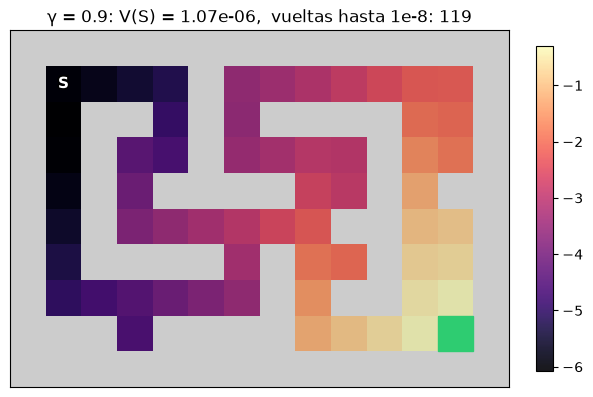

In [17]:
gamma_ej = 0.9   # TODO: probá 0.5, 0.9, 0.999

h = iterar(P, R, gamma_ej, K=20000)
cambios = np.abs(np.diff(np.array(h), axis=0)).max(axis=1)
k_fin = int(np.argmax(cambios < 1e-8)) if (cambios < 1e-8).any() else None
plot_cave(env, values=log10_seguro(h[-1]),
          title=f"γ = {gamma_ej}: V(S) = {h[-1][env.start]:.2e},  vueltas hasta 1e-8: {k_fin}")
plt.show()

## ✍️ Ejercicio 2 — Otra política, otra matriz

Cambiá `pi_ej`, las probabilidades de elegir ↑ → ↓ ← (tienen que sumar 1). Probá un agente que prefiere bajar y ir a la derecha, por ejemplo `[0.1, 0.4, 0.4, 0.1]`. ¿Cambia $P^\pi$? ¿Siguen sumando 1 sus filas? ¿Sube el valor de S?

¿filas suman 1? True


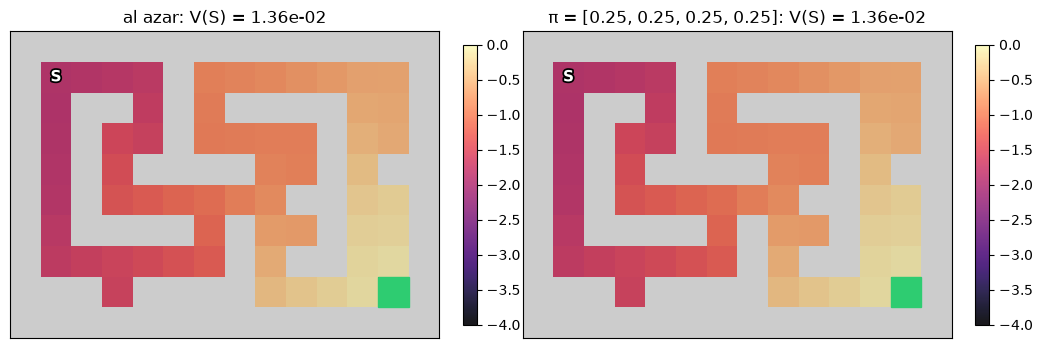

In [18]:
pi_ej = [0.25, 0.25, 0.25, 0.25]   # TODO: probá [0.1, 0.4, 0.4, 0.1]

P_ej, R_ej = matriz_politica(env, pi_ej)
V_ej = np.linalg.solve(np.eye(env.nS) - 0.99 * P_ej, R_ej)
print("¿filas suman 1?", np.allclose(P_ej.sum(axis=1), 1))
plot_row(env, [log10_seguro(V_exacto), log10_seguro(V_ej)],
         [f"al azar: V(S) = {V_exacto[env.start]:.2e}", f"π = {pi_ej}: V(S) = {V_ej[env.start]:.2e}"],
         clim=(-4, 0), size=5.2)

## Preguntas para pensar

1. $P^\pi$ es 95 % ceros. Si la cueva tuviera un millón de casillas, ¿cuánta memoria ocuparía guardarla entera? ¿Qué harías en cambio?
2. Con $\gamma = 1$ la matriz $I - P^\pi$ no tiene inversa (¿por qué? pista: el vector de unos). ¿Qué significa eso para el valor de una cueva sin descuento?
3. El gradiente del Paso 8 usa $P$, o sea, el mapa. ¿Cómo lo estimarías si solo pudieras **jugar** y anotar transiciones $(s, r, s')$?

## Próxima

La clase 1 (el marco) y después la 2: **¿qué es RL?** Ya tenemos las tres herramientas (Python, probabilidad y álgebra lineal) y vimos de reojo la ecuación de Bellman. Ahora apagamos la luz: un agente que no conoce el mapa, igual que un modelo de lenguaje que no conoce las reglas del idioma y las aprende a fuerza de ejemplos.

---

### Para profundizar

Este notebook es una adaptación libre (con otros ejemplos y otro recorrido) de:

- Zico Kolter (actualizado por Chuong Do), *Linear Algebra Review and Reference*, notas de repaso del curso CS229 (Stanford). https://cs229.stanford.edu/section/cs229-linalg.pdf
- Sutton y Barto, *Reinforcement Learning: An Introduction* (2ª ed.), cap. 4 (evaluación de políticas) y cap. 9–11 (aproximación de funciones y error de Bellman).
- Gilbert Strang, *Introduction to Linear Algebra*, cap. 6 (autovalores y matrices de Markov).